# Linked Fraud
**Do fraud rings catch fraud that a transaction-level model misses?**

Fraud models usually score one transaction at a time, but fraudsters often work in groups: one phone, many cards, many fake customers. This notebook rebuilds hidden customer identities from anonymized payment data, links them into a network, finds the rings, and asks how much extra fraud the ring view catches at the same review budget.

## The short answer
* **Rings are real.** Linking rebuilt identities that share a phone or card surfaces 44 rings whose transactions are 71% fraud, against a 3.5% base rate. Ring members start their fraud on the same day 56% of the time, against 0.6% for random pairs of fraudsters.
* **But a strong transaction model already catches them.** At a fixed review budget of 2% of transactions, the baseline model already flags 89% of the fraud inside rings. Adding network features moved recall from 42.4% to 42.6%, which is inside the seed-to-seed noise.
* **The decision:** on this data, a graph pipeline would add cost without catching more fraud. The rings are still valuable for investigators, because they explain *why* a cluster of transactions is fraud.

The rest of the notebook shows the work. Heavy code lives in `src/`; every output here can be rebuilt with `python src/pipeline.py`.

In [1]:
import sys
sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import display
import duckdb
duckdb.execute('SET enable_progress_bar = false')
import load, identity, model, graph, compare, patterns, hero, viz
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
P = model.PROCESSED

## 1. The data
The [IEEE-CIS Fraud Detection](https://www.kaggle.com/c/ieee-fraud-detection) data from Vesta: about 590,000 card-not-present e-commerce transactions over 182 days, with a fraud label. There is no customer ID, most columns are anonymized (C1 to C14, D1 to D15, V1 to V339), and only a quarter of transactions carry device data. Both files are loaded into DuckDB and joined on `TransactionID`.

In [2]:
con = load.connect()
s = load.summary(con)
display(s['overall'])
s['by_product']

,transactions,fraud_txns,fraud_rate_pct,pct_with_identity,first_day,last_day,span_days,total_amt,fraud_amt
0,590540,20663.0,3.5,24.4,1,182,182,79738949.0,3083845.0


,ProductCD,transactions,share_pct,fraud_rate_pct,pct_with_identity
0,W,439670,74.5,2.04,0.0
1,C,68519,11.6,11.69,90.8
2,R,37699,6.4,3.78,99.6
3,H,33024,5.6,4.77,99.6
4,S,11628,2.0,5.90,99.6


Fraud is rare (3.5%) and uneven: product C runs at 11.7% fraud, while product W, three quarters of all traffic, runs at 2.0% and never has device data. That last fact matters later, because rings are found mostly through shared devices.

## 2. Rebuilding hidden customers
Without a customer ID there is nothing to link. The trick, from the winning Kaggle solutions, is that `D1` counts days since the card's account started. So `day - D1` is the account's start date, which stays constant for the same customer. Combining it with the card and billing region gives a rebuilt identity:

```
uid = card1 + addr1 + (day - D1)
```

**Does it work?** In this data, once a customer is caught, their later transactions tend to be labeled fraud too. So a good identity should be "pure": all fraud or all clean. We compare against grouping by card alone, and against the same groups with labels shuffled at random.

In [3]:
con_id = identity.connect()
stats = identity.compare_groupings(con_id)
stats

groups  txns_covered  txns_per_group_mean  txns_per_group_median  pct_singletons  groups_2plus  pct_pure_2plus  fraud_groups_2plus  pct_all_fraud_given_any  \
grouping    labels                                                                                                                                                                    
card1 alone real       13553.0      590540.0                43.57                    4.0            25.4       10109.0            84.8              1594.0                      3.6   
            shuffled   13553.0      590540.0                43.57                    4.0            25.4       10109.0            65.0              3540.0                      0.0   
uid         real      217020.0      589271.0                 2.72                    1.0            57.4       92431.0            96.6              5087.0                     39.0   
            shuffled  217020.0      589271.0                 2.72                    1.0            57.4       92431.0            85.1             13774.0                      0.3   
uid + email real      272922.0      589271.0                 2.16                    1.0            64.7       96263.0            97.7              4821.0                     54.8   
            shuffled  272922.0      589271.0                 2.16                    1.0            64.7       96263.0            86.8             12750.0                      0.5   

                      pct_fraud_txns_in_pure_fraud_groups  
grouping    labels                                         
card1 alone real                                      0.9  
            shuffled                                  NaN  
uid         real                                     43.8  
            shuffled                                  0.4  
uid + email real                                     52.4  
            shuffled                                  0.6

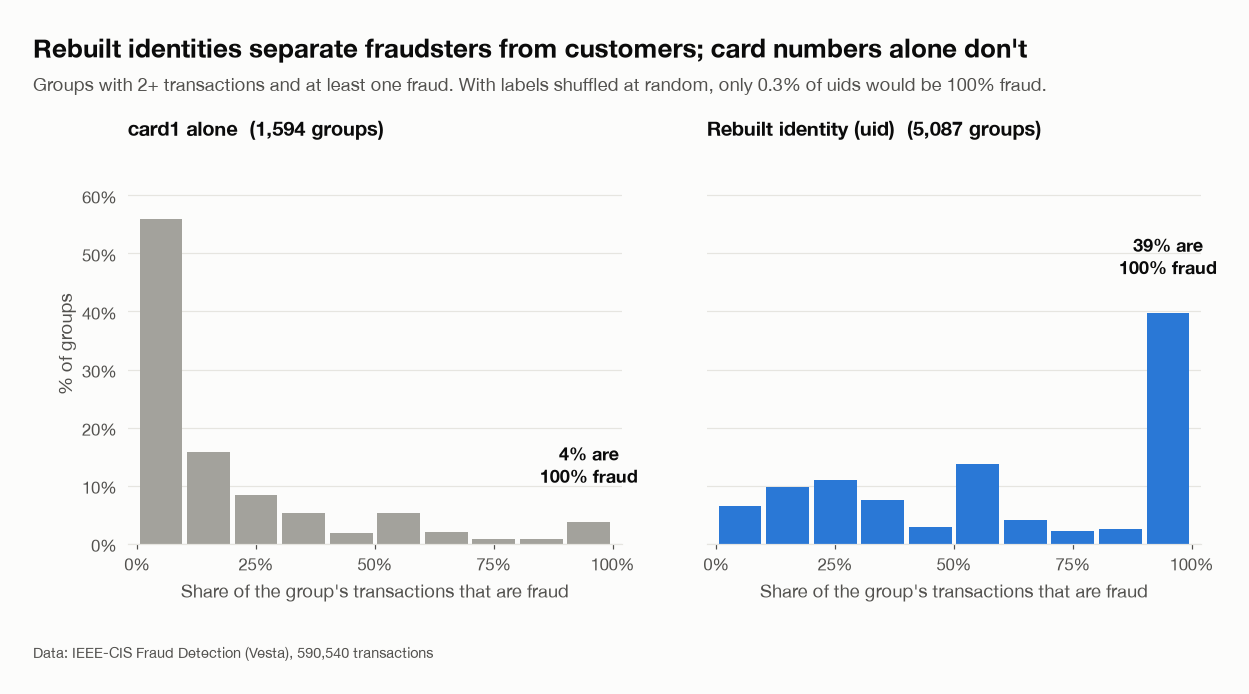

In [4]:
fig = identity.plot_purity(con_id, stats)

Among rebuilt identities with 2+ transactions, 96.6% are label-pure, against 84.8% for the card alone. More telling: of the identities that contain any fraud, 39% are *entirely* fraud, against 3.6% for the card alone and 0.3% when labels are shuffled. The rebuilt identity is approximate, but it is tracking real people.

## 3. The baseline: a transaction-level model
A LightGBM model on the original transaction fields plus velocity features written in DuckDB SQL (transactions in the last hour, day and week per card and per identity, distinct emails and devices, amount versus the customer's average).

Two rules keep the evaluation honest:
* **Time-based split.** Train on days 1 to 120, test on days 121 to 182. No random split, because fraud patterns drift.
* **Fixed review budget.** A fraud team can only review so much. We flag the top 2% of test transactions (3,520 of 175,998) and measure what share of fraud lands in that queue. The same budget is used everywhere.

Identity-level fraud labels are never used as features, since that would leak the answer.

In [5]:
sc = pd.read_csv(P / 'seed_check.csv')
sc.groupby('variant')[['auc', 'recall_at_budget', 'precision_at_budget', 'fraud_amt_caught']].agg(['mean', 'std']).round(4)

auc         recall_at_budget         precision_at_budget         fraud_amt_caught            
                    mean     std             mean     std                mean     std             mean         std
variant                                                                                                           
+ velocity        0.9208  0.0016           0.4249  0.0038              0.7318  0.0066         340219.0  10548.7142
transaction only  0.9216  0.0007           0.4224  0.0038              0.7275  0.0064         337351.0   4340.9790

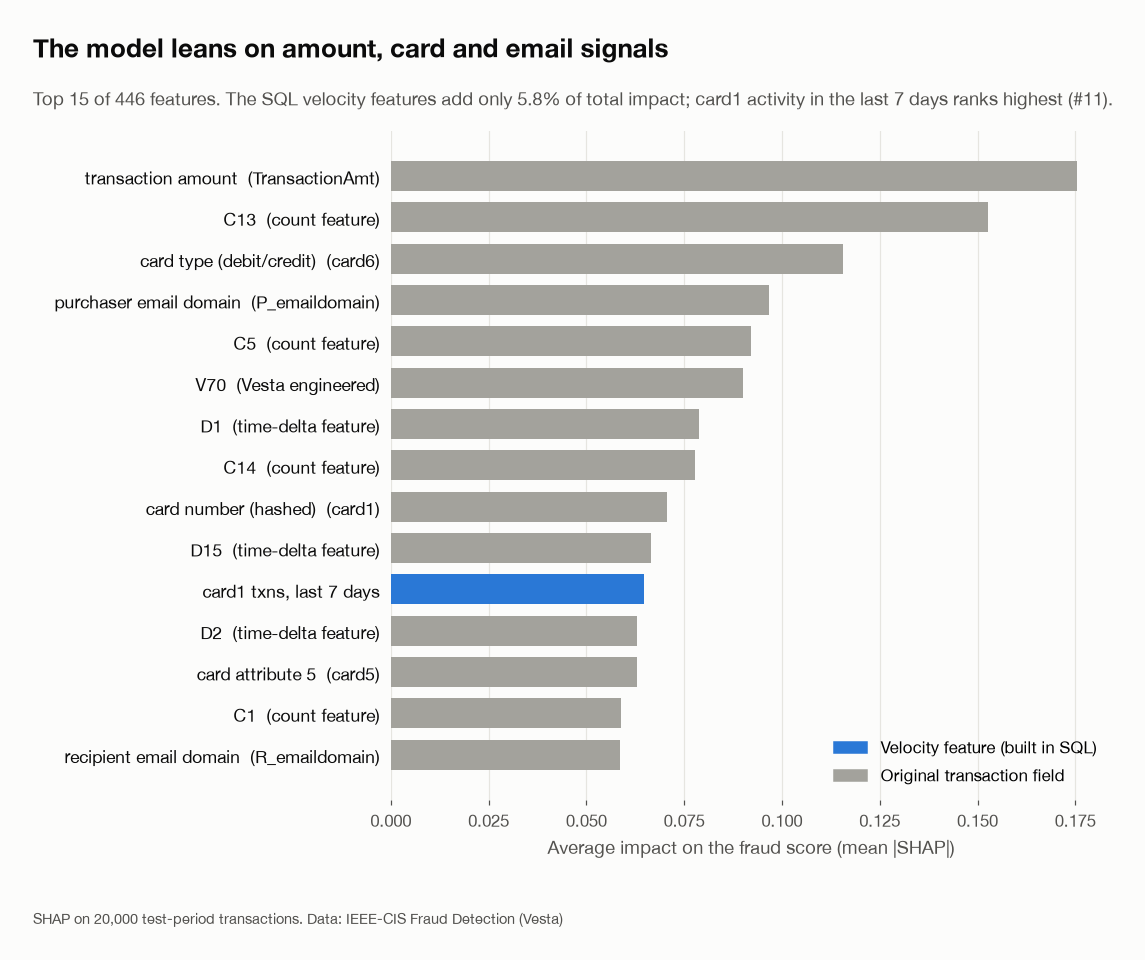

In [6]:
imp = pd.read_csv(P / 'shap_baseline.csv', index_col=0).iloc[:, 0]
fig = model.plot_shap(imp, *model.shap_title(imp))

The baseline catches about 42% of test fraud within the 2% budget, at roughly 73% precision (AUC 0.92). The velocity features I built are honest but redundant: across 3 seeds they do not move recall, because Vesta's own count and time-delta fields (C and D columns) already encode much of the same history.

## 4. Finding rings
**Nodes** are rebuilt identities. **Edges** join identities that share:
* a **device fingerprint** (device model + OS + browser + screen resolution),
* a **card** (same card1, different billing region or account start),
* a **rare email domain**.

**Hub suppression** is the key design choice: any value shared by more than 10 identities is dropped, so "Windows" or "gmail.com" cannot glue strangers together. At a threshold of 20, chains of popular values merge 20,000 identities into one blob. Clusters are connected components, with Louvain community detection splitting the few large ones.

**Leakage rule:** clusters are scored only with labels from the training period. A **ring** is a cluster with 3+ identities, fraud spread across 2+ of them, and a training fraud rate of at least 50%.

In [7]:
edges = pd.read_parquet(graph.EDGES_PARQUET)
clusters = pd.read_parquet(graph.CLUSTERS_PARQUET)
c = pd.read_parquet(P / 'cluster_table.parquet')
print({'linked identities': len(clusters), 'edges': len(edges), 'clusters': c.shape[0], 'rings': int(graph.is_ring(c).sum())})
c[graph.is_ring(c)].head(10)

{'linked identities': 35567, 'edges': 83677, 'clusters': 7181, 'rings': 44}


,n_uids,train_txns,train_fraud,train_fraud_uids,uids_with_train,test_txns,total_amt,train_fraud_rate,via_device,via_card,via_email
cluster_id,,,,,,,,,,,
2440,4,5,5.0,4,4,1,486.0,1.0000,1.0,0.0,0.0
3573,3,4,4.0,3,3,0,1200.0,1.0000,1.0,0.0,0.0
3701,3,4,4.0,3,3,0,1200.0,1.0000,1.0,0.0,0.0
3931,3,16,16.0,3,3,0,322.0,1.0000,1.0,0.0,0.0
4146,3,5,5.0,3,3,0,1375.0,1.0000,1.0,0.0,0.0
1886,5,2,2.0,2,2,5,1018.0,1.0000,1.0,0.0,0.0
2556,4,4,4.0,2,2,11,2753.0,1.0000,1.0,0.0,0.0
2614,4,3,3.0,2,2,2,184.0,1.0000,0.0,1.0,0.0
3440,3,3,3.0,2,2,1,520.0,1.0000,0.0,1.0,0.0


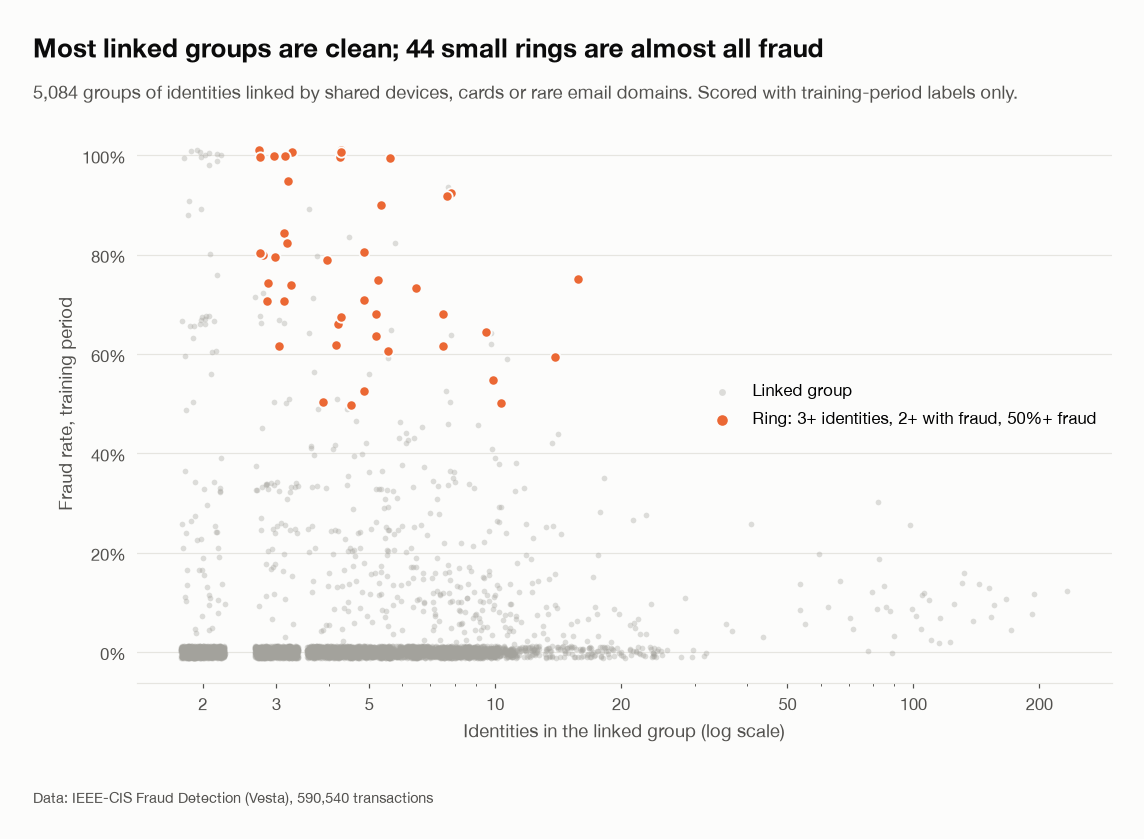

In [8]:
fig = graph.plot_size_vs_fraud(c)

Almost every linked group is clean. The 44 rings stand out as small (median 4 identities), mostly device-linked, and heavily fraudulent. Linking itself does not imply fraud; the network only becomes useful once you know some of the nodes are bad.

In [9]:
tv = graph.test_view(graph.connect(), clusters)
graph.gate_metrics(tv, c)

{'ring_clusters': 44,
 'uids_in_rings': 225,
 'test_base_fraud_rate': 0.0344,
 'in_ring (any)': {'txns': 114,
  'fraud_rate': 0.64,
  'pct_of_test_fraud': 1.2,
  'pct_of_missed_fraud': 1.2,
  'missed_fraud_amt': 2079},
 'in_ring, own history clean': {'txns': 52,
  'fraud_rate': 0.385,
  'pct_of_test_fraud': 0.3,
  'pct_of_missed_fraud': 0.1,
  'missed_fraud_amt': 226},
 'any fraud neighbor, own history clean': {'txns': 10178,
  'fraud_rate': 0.115,
  'pct_of_test_fraud': 19.4,
  'pct_of_missed_fraud': 10.1,
  'missed_fraud_amt': 19248}}

In the test period, ring transactions are 64% fraud, and identities with a clean history but a known-fraud neighbor run at 3.3 times the base fraud rate. The signal is real. The question is whether it is *new*.

## 5. Model versus rings, same budget
Four ways to fill the same 3,520-transaction review queue:
1. **Baseline model** alone
2. **Ring flag alone**: every test transaction whose identity sits in a ring
3. **Model + ring alert**: ring transactions jump the queue, the model fills the rest
4. **Model + network features**: the baseline plus 11 network features (neighbor fraud counts, cluster fraud rate, degree), retrained

Network features are built **as of** each transaction's date: a link only counts once both identities have shown the shared value, neighbor labels stop at day 120 for test rows (and lag 30 days for training rows), and an identity's own labels are never used. Each model is trained with 3 seeds.

In [10]:
df = compare.load_frame()
train, test = model.split(df)
scores = pd.read_parquet(compare.RESULTS_PARQUET)
r, missed = compare.compare(test, scores)
r[['fraud_caught', 'recall', 'fraud_amt_caught', 'precision']].round(4)

fraud_caught           recall         fraud_amt_caught            precision        
                                 mean      std    mean     std             mean        std      mean     std
approach                                                                                                    
Baseline model              2571.6667  21.1266  0.4242  0.0035      338557.3557  4428.6240    0.7306  0.0060
Ring flag alone               73.0000   0.0000  0.0120  0.0000        5326.7530     0.0000    0.6404  0.0000
Model + ring alert          2563.6667  23.1157  0.4228  0.0038      334694.9727  6093.6479    0.7283  0.0066
Model + network features    2585.3333   9.2376  0.4264  0.0015      341117.4273   382.8921    0.7345  0.0026

In [11]:
missed[['baseline_missed', 'newly_caught', 'pct_of_missed_caught', 'newly_caught_amt', 'baseline_catches_lost', 'net_fraud_gain', 'net_amt_gain']].round(3)

baseline_missed         newly_caught         pct_of_missed_caught        newly_caught_amt           baseline_catches_lost         net_fraud_gain         net_amt_gain  \
                                    mean     std         mean     std                 mean    std             mean       std                  mean     std           mean     std         mean   
approach                                                                                                                                                                                         
Ring flag alone                 3491.333  21.127        8.000   6.083                0.002  0.002          427.204   272.702              2506.667  26.951      -2498.667  21.127  -333230.603   
Model + ring alert              3491.333  21.127        8.000   6.083                0.002  0.002          427.204   272.702                16.000   4.359         -8.000   2.000    -3862.383   
Model + network features        3491.333  21.127      120.667  10.214                0.035  0.003        25364.186  3105.327               107.000  23.302         13.667  13.204     2560.072   

                                    
                               std  
approach                            
Ring flag alone           4428.624  
Model + ring alert        2665.462  
Model + network features  4274.941

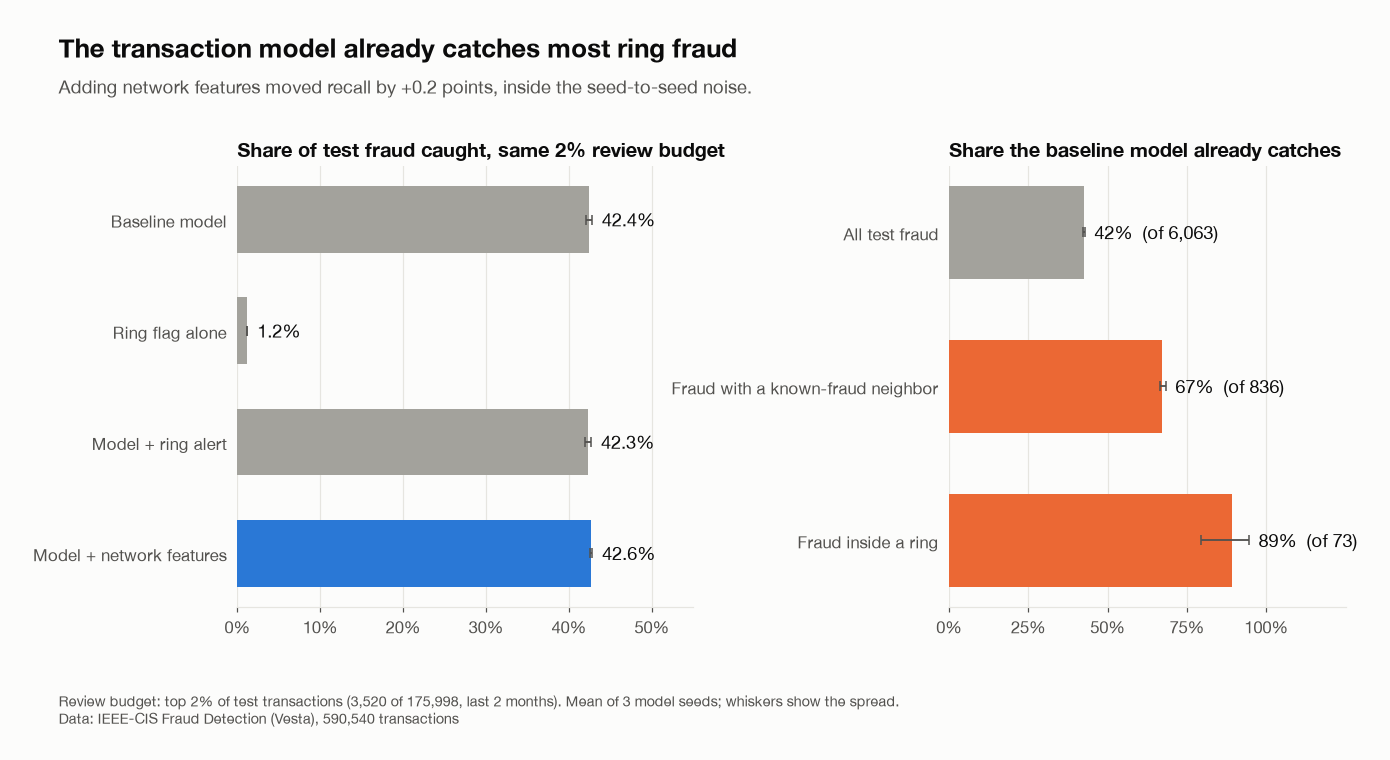

In [12]:
cov = compare.coverage(test, scores)
fig = compare.plot_headline(r, cov)

In [13]:
n = missed.loc['Model + network features']
print(f"Network features caught {n[('pct_of_missed_caught','mean')]:.1%} of the fraud the baseline missed "
      f"(${n[('newly_caught_amt','mean')]:,.0f}), but pushed out {n[('baseline_catches_lost','mean')]:.0f} baseline catches. "
      f"Net: {n[('net_fraud_gain','mean')]:+.0f} fraud transactions (std {n[('net_fraud_gain','std')]:.0f}), "
      f"{n[('net_amt_gain','mean')]:+,.0f} dollars.")

Network features caught 3.5% of the fraud the baseline missed ($25,364), but pushed out 107 baseline catches. Net: +14 fraud transactions (std 13), +2,560 dollars.


**The headline, stated honestly.** Network features caught about 3.5% of the fraud the transaction model missed, worth about $25K, but they displaced about as many catches as they added, so the net gain sits inside the noise. The ring flag alone is precise (64% fraud) but tiny (1.2% of test fraud), and putting ring alerts first slightly *hurts*, because the model was already catching that fraud.

**Why:** the transaction model already flags 89% of the fraud inside rings and 67% of fraud with a known-fraud neighbor, against 42% overall. The links are built from cards, devices and emails, which are already model inputs, and Vesta's C columns already count things like "addresses tied to this card". The network re-finds what the model sees.

**Business read:** a rigorous comparison stopped us from shipping a graph system that would add cost, latency and alert volume for no net gain in caught fraud. That is a result, not a failure.

## 6. What rings look like
Rings were chosen with training labels only; here we describe them with all labels, which is fine because nothing below feeds a model.

In [14]:
t = patterns.ring_frame(graph.connect())
patterns.ring_shape(t)

{'rings': 44,
 'identities': 225,
 'median_size': 4.0,
 'max_size': 16,
 'device_link_share': 0.67,
 'card_link_share': 0.34,
 'email_link_share': 0.0,
 'ring_txns': 545,
 'ring_fraud_rate': 0.712,
 'median_fraud_txns_per_member': 1.0,
 'members_with_1_or_2_fraud_txns': 0.775,
 'median_fraud_days': 13.5,
 'rings_fraud_in_one_day': 0.341}

,pairs,same_day,within_7_days,median_gap_days
group,,,,
Ring members,107,0.561,0.776,0.0
Random pairs of fraudsters,50000,0.006,0.082,52.0


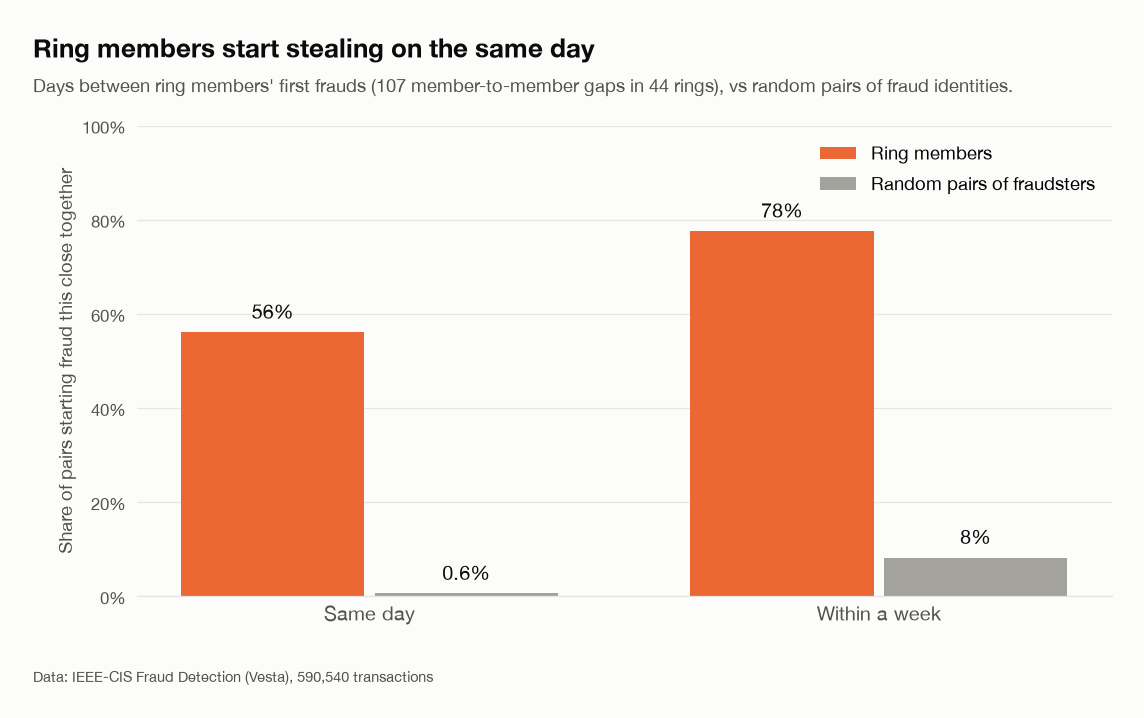

In [15]:
co = patterns.coordination(t)
display(co.round(3))
fig = patterns.plot_coordination(co)

In [16]:
m = patterns.mix(t)
display(m['device'].round(3)); display(m['amount_and_hour'].round(3))

DeviceType,desktop,mobile
segment,,
Ring,0.429,0.571
Other fraud,0.499,0.501
Clean,0.614,0.386


,median_amount,share_0_to_6h
segment,,
Ring,70.702,0.240
Other fraud,75.000,0.288
Clean,68.500,0.250


Findings, each backed by the numbers above:
1. **Rings are small and share a phone.** Median 4 identities; 67% of links come from a shared device and none from email. Each identity is close to throwaway: the median member commits 1 fraud transaction.
2. **Ring members move in lockstep.** 56% of members start their fraud on the same day as another member, against 0.6% for random pairs of fraudsters (78% vs 8% within a week).
3. **Rings burn out fast.** Fraud inside a ring runs a median of 13.5 days, and a third of rings do all their damage in a single day.
4. **Rings lean mobile but look ordinary otherwise.** 57% of ring transactions are on mobile, against 39% for clean traffic, but amounts and time of day match clean traffic.
5. **The model already sees them.** 89% of ring fraud is caught by the transaction model alone.

One caveat: we cannot tell whether a ring is several people or one person with several cards. "Coordinated" is the accurate word.

## 7. Case study: one phone, six cards
Chosen by a rule fixed before reading any ring's story: purely device-linked, 6+ identities, highest training fraud rate.

In [17]:
cid = patterns.pick_case_study()
tx, who = patterns.case_study(graph.connect(), cid)
who

,txns,fraud,first_day,last_day,amount,card_brand
uid,,,,,,
16075_231_56,1,1,56,56,200.00,mastercard
1388_231_64,5,5,64,78,1086.95,mastercard
14182_231_64,3,3,64,86,600.00,mastercard
6019_231_64,2,2,64,64,350.00,visa
9479_231_69,1,1,69,69,200.00,mastercard
13844_231_71,1,1,71,71,200.00,visa
16075_231_71,2,1,71,71,317.00,mastercard


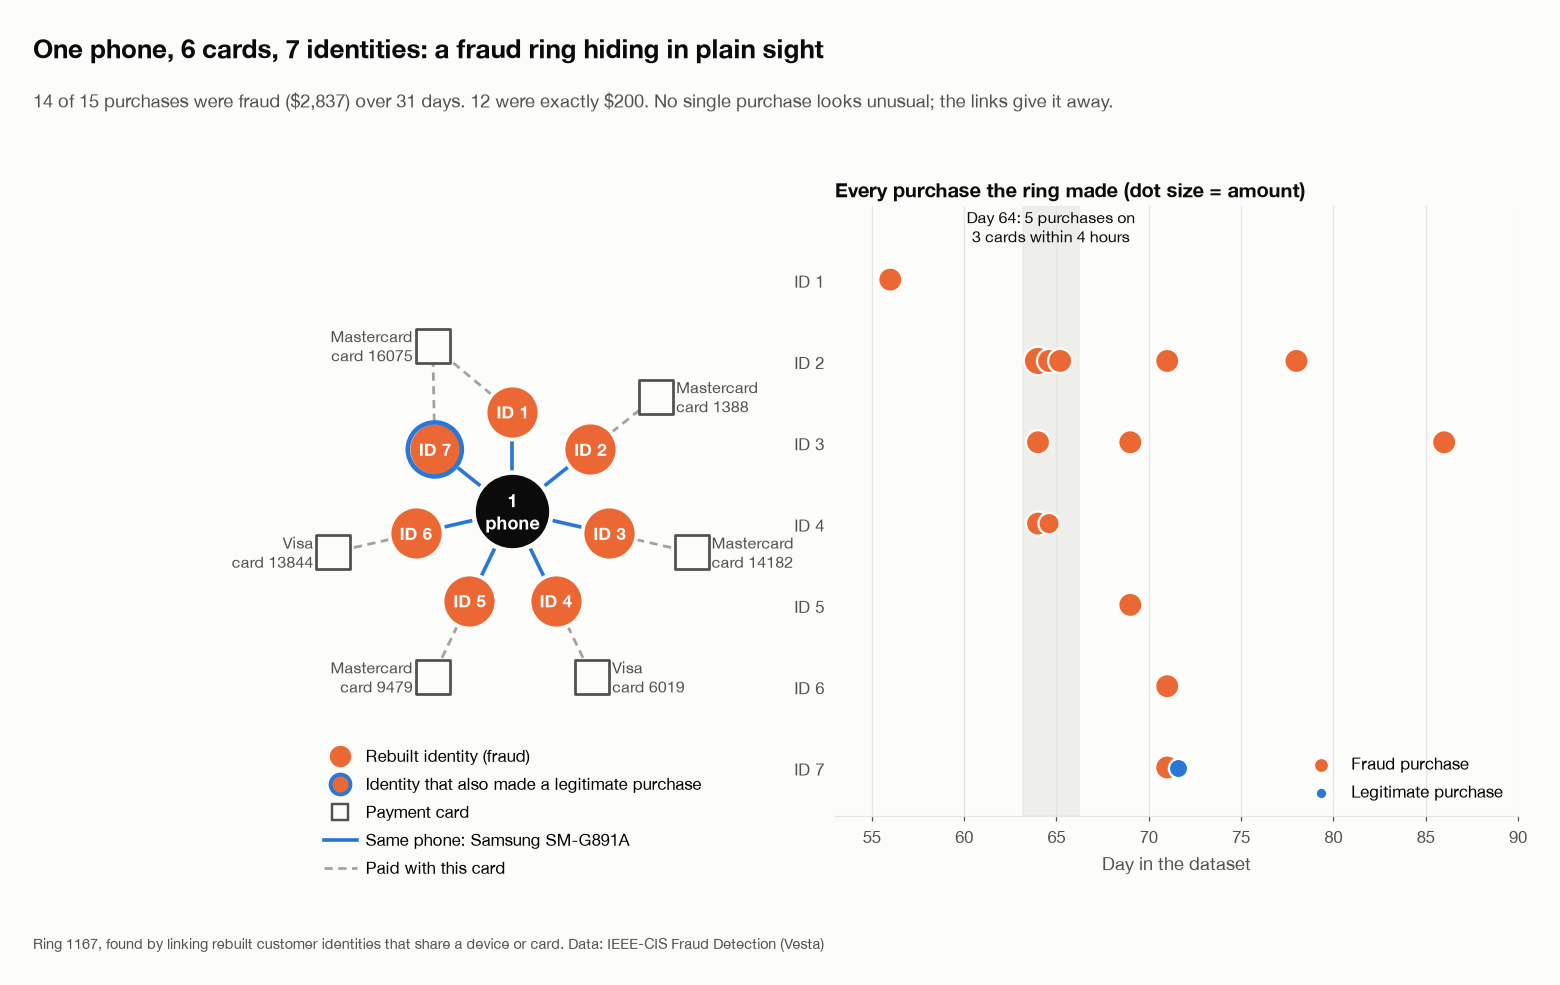

In [18]:
fig = hero.plot_hero(graph.connect(), cid)

On day 56 a Samsung phone makes a $200 purchase on a Mastercard billed to region 231. Eight days later the same phone is back, and within four hours makes five more purchases on three different cards, all with a yahoo.com email and the same billing region. Over the next three weeks it cycles through 6 cards and 7 rebuilt identities, and 12 of its 15 purchases are exactly $200. Fourteen of the fifteen are fraud ($2,837), and then it goes quiet. No single purchase looks unusual; the links give it away.

## 8. Where this pattern shows up in the real world
The same "one actor, many identities" shape appears well beyond card fraud:
* **Free-trial abuse in SaaS:** one person signs up again and again with new emails to avoid paying. Shared devices and payment fingerprints link the accounts.
* **Card testing at checkout:** a bot runs many stolen cards through small purchases from the same device or IP range to find the ones that work.
* **Promo and referral abuse:** fake accounts refer each other to farm sign-up credits, forming tight clusters that join and redeem within days of each other.
* **Marketplace seller rings:** colluding sellers and buyers boost ratings or launder payments; links through shared bank accounts, addresses or devices expose them.
* **Fake signups and bot farms:** bursts of new accounts created within hours of each other from a handful of devices.

The lessons carry over: suppress hub values, score clusters only with labels you would have had at the time, and measure the network against a strong baseline at a fixed review budget before building it.

## 9. Limits
* **Identities are approximate.** `card1 + addr1 + (day - D1)` is a reconstruction, not a true customer ID. Some real customers are split and some merged.
* **The data is anonymized.** Most columns are masked, so we cannot say what product H is or what C13 measures. Card IDs are hashed values, not card numbers.
* **Linkers are partial.** Device data exists for only 24% of transactions and never for product W, three quarters of traffic. A network with IP addresses, shipping addresses or bank accounts might find rings the model cannot see.
* **Labels spread after detection.** Vesta labels a customer's later transactions as fraud once they are caught, which makes identities look purer and can make ring signals look stronger than in live use.
* **Small numbers.** 44 rings and 114 test-period ring transactions; one ring alone accounts for 53 of them. Ring-level percentages carry wide uncertainty.
* **One dataset, one budget.** The conclusion that rings are redundant holds for this model on this data at a 2% budget. A weaker model, or a setting where fraudsters vary their transactions more, could change it.